# Swaptions : pricing tests

A payer (receiver) swaption of expiry $T_0$ and tenor $\Delta$ is the right to enter at $T_0$ into a swap paying
(receiving) the fixed rate $K$ until $T_0 + \Delta$. With the forward swap rate $S_0$ and the annuity $A_0$:
$$
\text{Payer} = A_0\, \mathbb{E}\left[(S_{T_0} - K)^+\right], \qquad \text{Receiver} = A_0\, \mathbb{E}\left[(K - S_{T_0})^+\right].
$$
1. European swaptions with the market models (Bachelier, Black, shifted Black) on a volatility grid.
2. The Hull-White model: European swaptions in closed form (Jamshidian), calibration to co-terminal swaptions,
   and **Bermudan** swaptions by Longstaff-Schwartz on the exact simulation.

> **The volatilities are illustrative.** No volatility quotes are available in `Data/`: the normal volatilities
> of `rates_market.py` are assumptions of the order of magnitude of EUR volatilities in early 2025 (70 to 90bp),
> with a flat smile. The curve is the EURIBOR 6M curve of 12/02/2025 (single-curve: it discounts and projects).

In [1]:
import os, sys, time
sys.path.append(os.path.abspath(os.path.join("..", "..")))   # Projets : Fixed_Income_Models package
sys.path.append(os.path.abspath(".."))                       # Produits : rate_products.py, rates_market.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from rates_market import eur_curve, illustrative_cap_vols, illustrative_swaption_vols
from rate_products import Swap, CapFloor, Swaption
from Fixed_Income_Models import (RatePricer, HullWhite, curve_risk, key_rate_risk, vega, bachelier, black,
                                 option_value, implied_vol)

pd.set_option("display.float_format", lambda x: f"{x:,.6g}")
curve = eur_curve()

In [2]:
vols = illustrative_swaption_vols()
pricer = RatePricer(curve, swaption_vols=vols, model="bachelier")
vols.to_frame().mul(1e4).round(1).rename_axis(index="expiry (y)", columns="tenor (y)")

tenor (y),1,2,3,5,10
expiry (y),,,,,
0.5,70,74,76,77,76
1,76,79,80,80,78
2,81,82,82,81,78
3,82,82,81,80,77
5,80,79,78,77,74


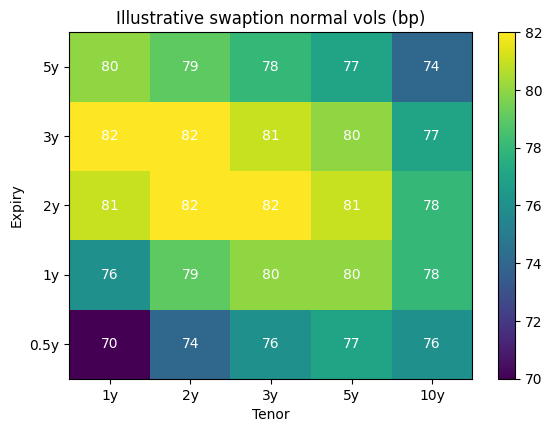

In [3]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
im = ax.imshow(1e4 * vols.vols, cmap="viridis", aspect="auto", origin="lower")
ax.set_xticks(range(len(vols.tenors))); ax.set_xticklabels([f"{t:g}y" for t in vols.tenors])
ax.set_yticks(range(len(vols.expiries))); ax.set_yticklabels([f"{e:g}y" for e in vols.expiries])
for i in range(len(vols.expiries)):
    for j in range(len(vols.tenors)):
        ax.text(j, i, f"{1e4 * vols.vols[i, j]:.0f}", ha="center", va="center", color="white")
ax.set_xlabel("Tenor"); ax.set_ylabel("Expiry"); ax.set_title("Illustrative swaption normal vols (bp)")
fig.colorbar(im, ax=ax); plt.show()

## 1. European swaptions

2y x 5y payer and receiver swaptions, notional 1,000,000.

In [4]:
payer = Swaption(2, 5, 0.025, payer=True)
receiver = Swaption(2, 5, 0.025, payer=False)
underlying = payer.underlying()
annuity, floating = pricer.swap_legs(underlying)
forward = floating / annuity
print(f"Forward swap rate 2y x 5y : {100 * forward:.4f}% | annuity : {annuity:,.2f} | normal vol : {1e4 * pricer.swaption_vol(payer):.1f}bp")
pd.Series({"Payer": pricer.price(payer), "Receiver": pricer.price(receiver),
           "Payer - Receiver": pricer.price(payer) - pricer.price(receiver),
           "Forward payer swap": pricer.price(underlying)}, name="value").to_frame()

Forward swap rate 2y x 5y : 2.3889% | annuity : 4,458,596.31 | normal vol : 81.0bp


,value
Payer,"17,995"
Receiver,"22,947.4"
Payer - Receiver,"-4,952.36"
Forward payer swap,"-4,952.36"


**Payer-receiver parity**: Payer - Receiver = forward payer swap (model free). The same Bachelier price is
recovered by the Black and shifted Black models with their implied volatilities.

In [5]:
rows = {}
for K in [0.015, 0.02, forward, 0.03, 0.035]:
    p = payer.with_strike(K)
    value = pricer.price(p)
    rows[f"K = {100 * K:.3f}%"] = {"Bachelier price": value, "normal vol (bp)": 1e4 * pricer.swaption_vol(p),
                                   "Black vol (%)": 100 * pricer.implied_swaption_vol(p, value, "black"),
                                   "shifted Black vol, 3% (%)": 100 * RatePricer(curve, swaption_vols=vols, model="shifted_black", shift=0.03).implied_swaption_vol(p, value)}
pd.DataFrame(rows).T

,Bachelier price,normal vol (bp),Black vol (%),"shifted Black vol, 3% (%)"
K = 1.500%,"46,036.9",81,43.0609,16.4634
K = 2.000%,"30,209",81,37.4409,15.6326
K = 2.389%,"20,375.5",81,34.238,15.0592
K = 3.000%,"9,585.11",81,30.4245,14.2622
K = 3.500%,"4,504.49",81,28.025,13.6873


## 2. Forms of European swaptions and Greeks

In [6]:
atm = lambda e, t: pricer.par_rate(Swaption(e, t, 0.0).underlying())
variants = {"Payer 2y x 5y K=2.5%": payer, "Receiver 2y x 5y K=2.5%": receiver,
            "Payer 2y x 5y ATM": payer.with_strike(atm(2, 5)), "Receiver 2y x 5y ATM": receiver.with_strike(atm(2, 5)),
            "Payer 1y x 1y ATM": Swaption(1, 1, atm(1, 1)), "Payer 1y x 10y ATM": Swaption(1, 10, atm(1, 10)),
            "Payer 5y x 5y ATM": Swaption(5, 5, atm(5, 5)), "Payer 3y x 2y ATM": Swaption(3, 2, atm(3, 2))}
rows = {}
for name, s in variants.items():
    risk = curve_risk(pricer, s)
    rows[name] = {"strike (%)": 100 * s.strike, "vol (bp)": 1e4 * pricer.swaption_vol(s), "value": risk["value"],
                  "DV01": risk["DV01 (per +1bp)"], "convexity": risk["convexity (per bp^2)"], "vega (per bp)": vega(pricer, s)}
pd.DataFrame(rows).T

,strike (%),vol (bp),value,DV01,convexity,vega (per bp)
Payer 2y x 5y K=2.5%,2.5,81,"17,995",201.608,1.4359,250.369
Receiver 2y x 5y K=2.5%,2.5,81,"22,947.4",-257.13,1.84356,250.369
Payer 2y x 5y ATM,2.38893,81,"20,375.5",218.051,1.42846,251.549
Receiver 2y x 5y ATM,2.38893,81,"20,375.5",-238.234,1.83481,251.549
Payer 1y x 1y ATM,2.17328,76,"2,899.13",48.2686,0.509434,38.1464
Payer 1y x 10y ATM,2.378,78,"26,814.3",423.463,4.10554,343.773
Payer 5y x 5y ATM,2.42391,77,"28,507.4",189.871,0.710625,370.225
Payer 3y x 2y ATM,2.38783,82,"10,222.8",87.7606,0.459479,124.668


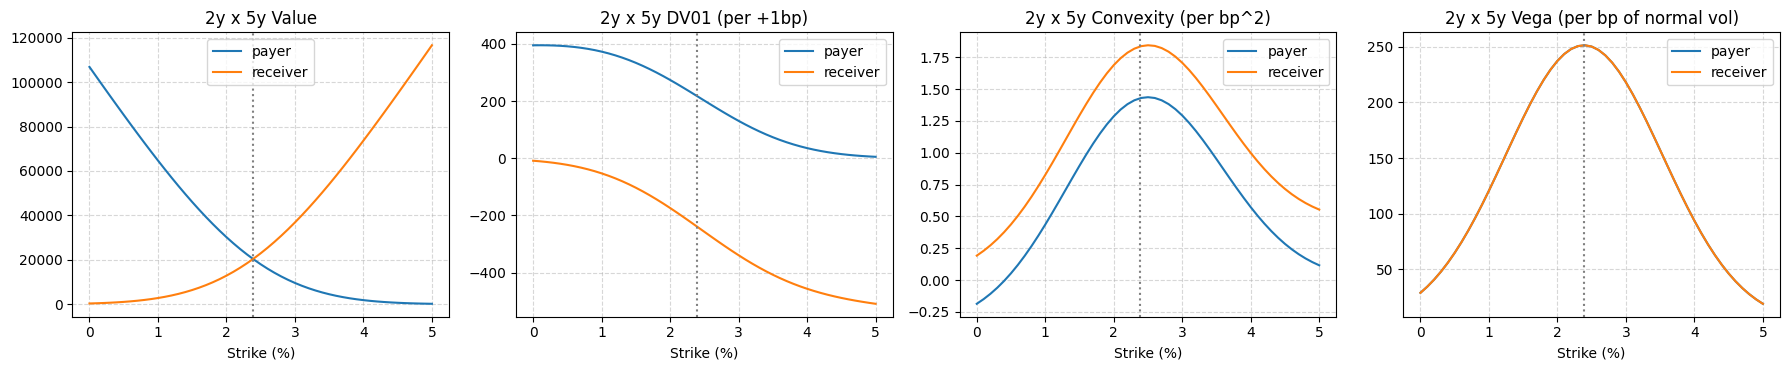

In [7]:
strikes = np.linspace(0.0, 0.05, 51)
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for is_payer in [True, False]:
    out = {"value": [], "DV01": [], "convexity": [], "vega": []}
    for k in strikes:
        s = Swaption(2, 5, k, payer=is_payer)
        r = curve_risk(pricer, s)
        out["value"].append(r["value"]); out["DV01"].append(r["DV01 (per +1bp)"]); out["convexity"].append(r["convexity (per bp^2)"]); out["vega"].append(vega(pricer, s))
    for ax, key in zip(axes, out):
        ax.plot(100 * strikes, out[key], label="payer" if is_payer else "receiver")
for ax, title in zip(axes, ["Value", "DV01 (per +1bp)", "Convexity (per bp^2)", "Vega (per bp of normal vol)"]):
    ax.axvline(100 * forward, color="grey", linestyle=":"); ax.set_title(f"2y x 5y {title}"); ax.set_xlabel("Strike (%)")
    ax.grid(True, linestyle="--", alpha=0.5); ax.legend()
plt.tight_layout(); plt.show()

## 3. Hull-White

**Validation**: Jamshidian closed form against Monte Carlo on the exact simulation, and payer-receiver parity.

In [8]:
hw = HullWhite(curve, a=0.03, sigma=0.0085)
rows = {}
for s in [payer, receiver, Swaption(1, 10, atm(1, 10)), Swaption(5, 5, atm(5, 5))]:
    mc = hw.bermudan_swaption(s, n_paths=200_000, seed=5)        # European : a single exercise date
    rows[s.code + f" K={100 * s.strike:.2f}%"] = {"Jamshidian": hw.price(s), "Monte Carlo": mc["price"], "MC std error": mc["stderr"],
                                                  "error / std error": (mc["price"] - hw.price(s)) / mc["stderr"]}
print("Hull-White payer - receiver - forward swap :", hw.price(payer) - hw.price(receiver) - pricer.price(underlying))
pd.DataFrame(rows).T

Hull-White payer - receiver - forward swap : -7.759808795526624e-09


,Jamshidian,Monte Carlo,MC std error,error / std error
Payer 2y x 5y K=2.50%,"17,385","17,351.4",43.3747,-0.773925
Receiver 2y x 5y K=2.50%,"22,337.4","22,300.9",51.3124,-0.711231
Payer 1y x 10y K=2.38%,"25,562.4","25,519.2",55.9234,-0.772469
Payer 5y x 5y K=2.42%,"27,852.5","27,806.7",54.5132,-0.841581


**Calibration to the co-terminal swaptions** (1y x 6y, 2y x 5y, ..., 6y x 1y, at the money), the natural hedges of
a 1y x 6y Bermudan swaption. Residuals in bp of normal volatility.

In [9]:
coterminals = [Swaption(e, 7 - e, atm(e, 7 - e)) for e in range(1, 7)]
hw = HullWhite(curve, a=0.03, sigma=0.008)
fit = hw.calibrate(pricer, coterminals)
print(hw, fit)
pd.DataFrame({"market vol (bp)": [1e4 * pricer.swaption_vol(s) for s in coterminals],
              "Hull-White implied vol (bp)": [1e4 * pricer.implied_swaption_vol(s, hw.price(s)) for s in coterminals]},
             index=[s.code for s in coterminals])

HullWhite(a=0.0189, sigma=83.3bp) {'a': 0.018871281092588867, 'sigma': 0.008332402922333452, 'RMSE (bp of normal vol)': 0.6674576691454649, 'max error (bp)': 1.0776808157725877}


,market vol (bp),Hull-White implied vol (bp)
Payer 1y x 6y,79.6,79.8671
Payer 2y x 5y,81,79.9223
Payer 3y x 4y,80.5,79.9318
Payer 4y x 3y,79.5,79.9462
Payer 5y x 2y,79,79.9579
Payer 6y x 1y,80,79.9743


## 4. Bermudan swaptions

A 1y x 6y (no-call 1 year, maturity 7 years) Bermudan payer swaption, exercisable every year into the remaining
swap. Longstaff-Schwartz gives a lower bound; an out-of-sample estimation of the exercise policy checks that the
in-sample estimate is not biased upwards. The Bermudan is worth more than the most expensive co-terminal European.

In [10]:
K = atm(1, 6)
bermudan = Swaption(1, 6, K, payer=True, exercise="bermudan")
start = time.time()
result = hw.bermudan_swaption(bermudan, n_paths=100_000, seed=1)
print(f"{bermudan} : {result['price']:,.2f} +/- {1.96 * result['stderr']:,.2f} (95%), {time.time() - start:.2f}s")
europeans = {f"European {T:g}y x {7 - T:g}y": hw.price(bermudan.european(T)) for T in bermudan.exercise_dates()}
summary = pd.Series({**europeans, "Bermudan (LSM)": result["price"]}, name="value").to_frame()
summary["Bermudan / European"] = result["price"] / summary["value"]
summary

Bermudan Payer 1y x 6y(K=2.3508%, N=1,000,000) : 27,518.81 +/- 102.23 (95%), 0.08s


,value,Bermudan / European
European 1y x 6y,"17,252.8",1.59504
European 2y x 5y,"20,960.7",1.31287
European 3y x 4y,"20,436.2",1.34657
European 4y x 3y,"17,551.9",1.56786
European 5y x 2y,"12,902.1",2.13289
European 6y x 1y,"6,952.99",3.95784
Bermudan (LSM),"27,518.8",1


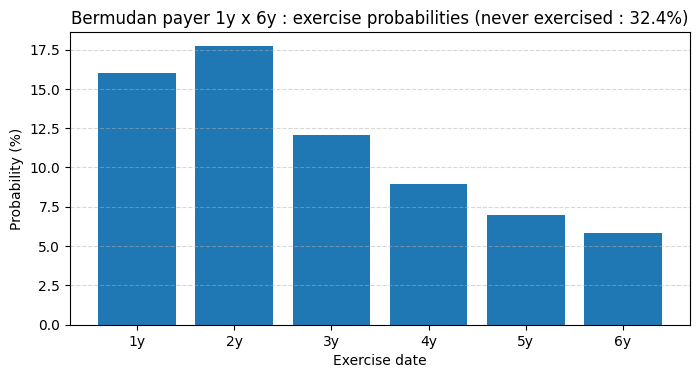

In [11]:
probabilities = result["exercise probability"]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar([f"{t:g}y" for t in probabilities], 100 * np.array(list(probabilities.values())))
ax.set_xlabel("Exercise date"); ax.set_ylabel("Probability (%)")
ax.set_title(f"Bermudan payer 1y x 6y : exercise probabilities (never exercised : {100 * (1 - sum(probabilities.values())):.1f}%)")
ax.grid(True, axis="y", linestyle="--", alpha=0.5); plt.show()

**Bermudan features.** Payer vs receiver, strikes, and the effect of the mean reversion $a$ at fixed co-terminal
fit: with a higher $a$, rates at different dates are less correlated and the switch option is worth more.

In [12]:
rows = {}
for name, s in {"Payer ATM": bermudan, "Receiver ATM": Swaption(1, 6, K, payer=False, exercise="bermudan"),
                "Payer K-50bp": bermudan.with_strike(K - 0.005), "Payer K+50bp": bermudan.with_strike(K + 0.005)}.items():
    r = hw.bermudan_swaption(s, n_paths=100_000, seed=1)
    rows[name] = {"Bermudan": r["price"], "std error": r["stderr"],
                  "max European": max(hw.price(s.european(T)) for T in s.exercise_dates())}
table = pd.DataFrame(rows).T
table["premium (%)"] = 100 * (table["Bermudan"] / table["max European"] - 1)
table

,Bermudan,std error,max European,premium (%)
Payer ATM,"27,518.8",52.1583,"20,960.7",31.2875
Receiver ATM,"25,739.8",60.3093,"19,262.9",33.624
Payer K-50bp,"41,835.8",58.3642,"34,285.2",22.0228
Payer K+50bp,"17,470",49.5517,"12,656.9",38.0276


In [13]:
rows = {}
for a in [0.001, 0.01, 0.03, 0.06, 0.10]:
    model = HullWhite(curve, a=a, sigma=0.008)
    fit = model.calibrate(pricer, coterminals, fixed={"a": a})
    r = model.bermudan_swaption(bermudan, n_paths=100_000, seed=1)
    best = max(model.price(bermudan.european(T)) for T in bermudan.exercise_dates())
    rows[f"a = {a:g}"] = {"sigma (bp)": 1e4 * model.sigma, "fit RMSE (bp)": fit["RMSE (bp of normal vol)"],
                          "Bermudan": r["price"], "max European": best, "premium (%)": 100 * (r["price"] / best - 1)}
pd.DataFrame(rows).T

,sigma (bp),fit RMSE (bp),Bermudan,max European,premium (%)
a = 0.001,78.3633,0.674095,"27,215.9","20,957.7",29.861
a = 0.01,80.8357,0.669086,"27,364.2","20,960.1",30.5539
a = 0.03,86.5176,0.67009,"27,699.4","20,959.2",32.1587
a = 0.06,95.5268,0.70771,"28,193.2","20,942.3",34.6229
a = 0.1,108.444,0.857233,"28,834.9","20,891.2",38.024


**Greeks of the Bermudan** (Hull-White calibrated above, common random numbers): curve DV01 and convexity with the
model refitted to the shifted curve, and vega with respect to the short rate volatility $\sigma$. The exercise policy
is re-estimated in every scenario, which adds noise to the finite differences: the curve is bumped by 10bp
(results per 1bp), since a 1bp bump makes the second difference dominated by this noise.

In [14]:
bermudan_pricer = lambda model: model.bermudan_swaption(bermudan, n_paths=100_000, seed=1)["price"]
base = bermudan_pricer(hw)
h = 10   # bp
up, down = bermudan_pricer(hw.with_curve(curve.shifted(h))), bermudan_pricer(hw.with_curve(curve.shifted(-h)))
vega_sigma = (bermudan_pricer(hw.with_vol_shift(1e-4)) - bermudan_pricer(hw.with_vol_shift(-1e-4))) / 2
pd.Series({"value": base, "DV01 (per +1bp)": (up - down) / (2 * h), "convexity (per bp^2)": (up - 2 * base + down) / h**2,
           "vega (per +1bp of sigma)": vega_sigma}, name="Bermudan payer 1y x 6y").to_frame()

,Bermudan payer 1y x 6y
value,"27,518.8"
DV01 (per +1bp),236.686
convexity (per bp^2),1.72321
vega (per +1bp of sigma),324.023


## 5. Limitations

Illustrative volatilities with a flat smile; one-factor model (rates perfectly correlated across maturities, which
limits the switch value of Bermudans); single curve; Longstaff-Schwartz is a lower bound.